In [4]:
# ---------------------------------------------------------------------------
# 0. Import Libraries and Reproducibility setup
# ---------------------------------------------------------------------------
import os
import sys
import numpy
import scipy
import matplotlib
import sklearn
import numpy as np
import matplotlib.pyplot as plt
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import Matern, ConstantKernel, WhiteKernel
from scipy.stats import norm, spearmanr, skew
from scipy.optimize import minimize

SEED = 42                                                 # Random seed 
rng = np.random.default_rng(SEED)

print("=" * 100)
print("Software and Libraries used")
print("=" * 100)
print(f"  python      : {sys.version.split()[0]}")
print(f"  numpy       : {np.__version__}")
print(f"  scipy       : {scipy.__version__}")
print(f"  scikit-learn: {sklearn.__version__}")
print(f"  matplotlib  : {matplotlib.__version__}")
print(f"  SEED        : {SEED}")
print()


# ---------------------------------------------------------------- 
# Figures setup
# ---------------------------------------------------------------- 
SURFACE, INK, INK2, MUTED, GRIDC = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e6e5e1"
BLUE, ORANGE, AQUA, YELLOW, MAGENTA = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "font.size": 10, "text.color": INK, "axes.edgecolor": MUTED, "axes.labelcolor": INK2,
    "xtick.color": MUTED, "ytick.color": MUTED, "xtick.labelcolor": INK2, "ytick.labelcolor": INK2,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
    "grid.color": GRIDC, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
})


Software and Libraries used
  python      : 3.13.9
  numpy       : 2.3.5
  scipy       : 1.16.3
  scikit-learn: 1.9.0
  matplotlib  : 3.11.1
  SEED        : 42



In [ ]:
# ---------------------------------------------------------------------------
# 1. Load data
# ---------------------------------------------------------------------------
X = np.load('..\Function_2_Data\Week_11_Data/F2_Week_11_inputs.npy')
y = np.load('..\Function_2_Data\Week_11_Data/F2_Week_11_outputs.npy')
n, d = X.shape
N_INITIAL = 10
print(f"n = {n} ({N_INITIAL} initial + {n - N_INITIAL} queried); newest point x = {X[-1]}, y = {y[-1]:.6f}")

n = 20 (10 initial + 10 queried); newest point x = [0.69 0.45], y = 0.618120


raw y: mean 0.3756, std 0.2458, skew -0.477, range [-0.0656, 0.6951]
Raw y:          mean=0.3756, std=0.2458, min=-0.0656, max=0.6951
Standardized y: mean=-0.0000, std=1.0000


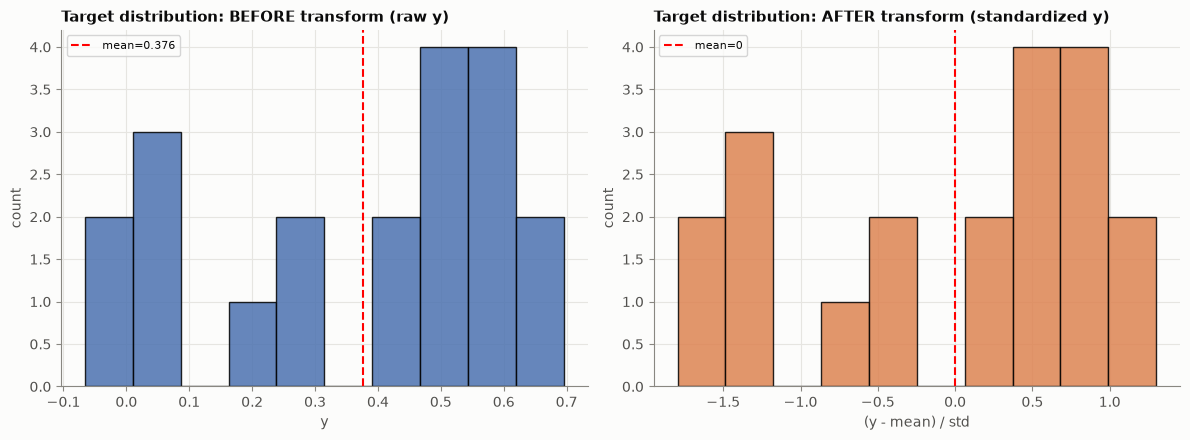

In [5]:
# ---------------------------------------------------------------------------
# 2a. Input transformation (unchanged)
# ---------------------------------------------------------------------------
# Inputs already live in [0,1] x [0,1] -- no rescaling needed.
bounds = np.array([[0.0, 1.0], [0.0, 1.0]])

# ---------------------------------------------------------------------------
# 2b. Output transformation: standardize y
# ---------------------------------------------------------------------------
y_mean, y_std = y.mean(), y.std()
y_scaled = (y - y_mean) / y_std
obs = int(np.argmax(y))

def unscale_y(y_s):
    return y_s * y_std + y_mean      # Map standardized y back to original units.

fig_dist, axes_dist = plt.subplots(1, 2, figsize=(12, 4.5))

axes_dist[0].hist(y, bins=10, color="#4C72B0", edgecolor="black", alpha=0.85)
axes_dist[0].axvline(y_mean, color="red", linestyle="--", linewidth=1.5, label=f"mean={y_mean:.3f}")
axes_dist[0].set_title("Target distribution: BEFORE transform (raw y)")
axes_dist[0].set_xlabel("y"); axes_dist[0].set_ylabel("count")
axes_dist[0].legend(fontsize=8)

axes_dist[1].hist(y_scaled, bins=10, color="#DD8452", edgecolor="black", alpha=0.85)
axes_dist[1].axvline(0.0, color="red", linestyle="--", linewidth=1.5, label="mean=0")
axes_dist[1].set_title("Target distribution: AFTER transform (standardized y)")
axes_dist[1].set_xlabel("(y - mean) / std"); axes_dist[1].set_ylabel("count")
axes_dist[1].legend(fontsize=8)

plt.tight_layout()

print(f"raw y: mean {y_mean:.4f}, std {y_std:.4f}, skew {skew(y):.3f}, range [{y.min():.4f}, {y.max():.4f}]")
print(f"Raw y:          mean={y_mean:.4f}, std={y_std:.4f}, min={y.min():.4f}, max={y.max():.4f}")
print(f"Standardized y: mean={y_scaled.mean():.4f}, std={y_scaled.std():.4f}")


c:\Users\Ilias\anaconda3\Lib\site-packages\sklearn\gaussian_process\kernels.py:445: ConvergenceWarning: The optimal value found for dimension 0 of parameter k1__k2__length_scale is close to the specified lower bound 0.05. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(
c:\Users\Ilias\anaconda3\Lib\site-packages\sklearn\gaussian_process\kernels.py:455: ConvergenceWarning: The optimal value found for dimension 1 of parameter k1__k2__length_scale is close to the specified upper bound 1.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
c:\Users\Ilias\anaconda3\Lib\site-packages\sklearn\gaussian_process\kernels.py:455: ConvergenceWarning: The optimal value found for dimension 1 of parameter k1__k2__length_scale is close to the specified upper bound 10.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
c:\Users\Ilias\anaconda3\Lib\site-packages\sklearn\gaussian_process\kernels.py:4


KERNEL COMPARISON (standardised y; LOO with hyperparameters fixed at the full fit)
  Week-10: ARD Matern 5/2, bounds 0.05-1       ls=[0.05 1.  ] noise sd=0.0544 LML=-17.95 LOO RMSE/std=0.629 Spearman=0.773 mean log pred density=-0.617
  ARD Matern 5/2, bounds 0.05-10               ls=[ 0.0781 10.    ] noise sd=0.0648 LML=-16.43 LOO RMSE/std=0.596 Spearman=0.789 mean log pred density=-0.532
  ARD Matern 3/2, bounds 0.05-10               ls=[ 0.0856 10.    ] noise sd=0.0622 LML=-16.60 LOO RMSE/std=0.613 Spearman=0.789 mean log pred density=-0.560
  Isotropic Matern 5/2, bounds 0.05-10         ls=[0.05] noise sd=0.0340 LML=-23.54 LOO RMSE/std=0.860 Spearman=0.695 mean log pred density=-0.986

Recommended model: incumbent by posterior mean = row 17 [0.704881 0.      ], mean 0.6024 (observed 0.6951); noise sd 0.0648


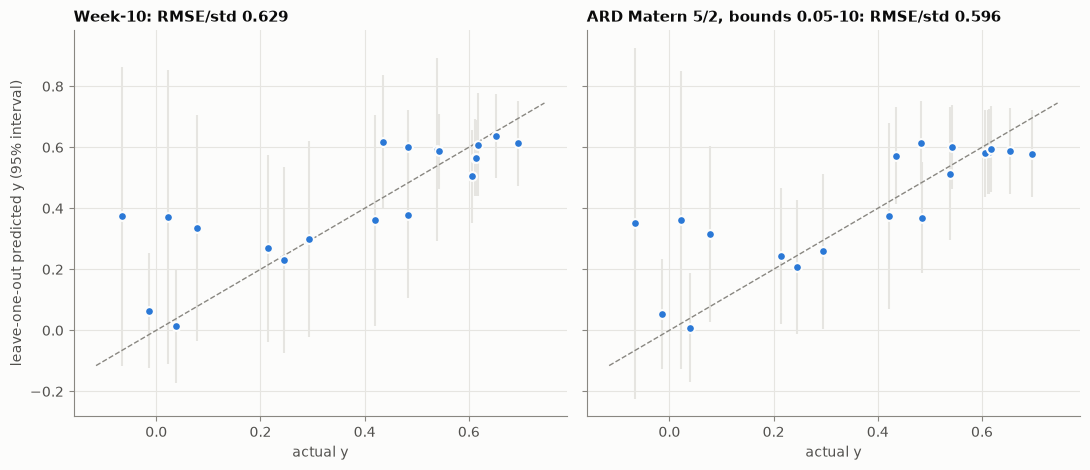

In [7]:
# ---------------------------------------------------------------------------
# 3. Surrogate models
# ---------------------------------------------------------------------------

t = y_scaled

def fit(ls0, bounds, nu=2.5):
    k = (ConstantKernel(1.0, (1e-3, 1e3)) * Matern(length_scale=ls0, length_scale_bounds=bounds, nu=nu)
         + WhiteKernel(1e-3, (1e-8, 2e-1)))
    return GaussianProcessRegressor(kernel=k, n_restarts_optimizer=20, random_state=SEED).fit(X, t)

def loo(gp):
    mu, sd = np.empty(n), np.empty(n)
    for i in range(n):
        keep = np.arange(n) != i
        g = GaussianProcessRegressor(kernel=gp.kernel_, optimizer=None).fit(X[keep], t[keep])
        a, b = g.predict(X[i:i + 1], return_std=True)
        mu[i], sd[i] = a[0], b[0]
    return mu, sd

variants = {
    "Week-10: ARD Matern 5/2, bounds 0.05-1": fit([0.3, 0.3], (0.05, 1.0)),
    "ARD Matern 5/2, bounds 0.05-10": fit([0.3, 0.3], (0.05, 10.0)),
    "ARD Matern 3/2, bounds 0.05-10": fit([0.3, 0.3], (0.05, 10.0), nu=1.5),
    "Isotropic Matern 5/2, bounds 0.05-10": fit(0.3, (0.05, 10.0)),
}
CURRENT, REC = list(variants)[0], list(variants)[1]
loos = {}
print("\nKERNEL COMPARISON (standardised y; LOO with hyperparameters fixed at the full fit)")
for name, gp in variants.items():
    mu, sd = loo(gp)
    loos[name] = (mu, sd)
    ls = np.atleast_1d(gp.kernel_.k1.k2.length_scale)
    print(f"  {name:44s} ls={np.round(ls, 4)} noise sd={np.sqrt(gp.kernel_.k2.noise_level) * y_std:.4f} "
          f"LML={gp.log_marginal_likelihood_value_:.2f} LOO RMSE/std={np.sqrt(np.mean((t - mu) ** 2)):.3f} "
          f"Spearman={spearmanr(t, mu)[0]:.3f} mean log pred density={np.mean(norm.logpdf(t, mu, sd)):.3f}")

gp = variants[REC]
noise_var = gp.kernel_.k2.noise_level
noise_sd_raw = np.sqrt(noise_var) * y_std

def latent(Z, model=gp):
    mu, s = model.predict(Z, return_std=True)
    return mu, np.sqrt(np.maximum(s ** 2 - model.kernel_.k2.noise_level, 1e-18))

mu_tr, _ = latent(X)
inc = int(np.argmax(mu_tr))
f_inc = mu_tr[inc]
print(f"\nRecommended model: incumbent by posterior mean = row {inc} {X[inc]}, "
      f"mean {mu_tr[inc] * y_std + y_mean:.4f} (observed {y[inc]:.4f}); noise sd {noise_sd_raw:.4f}")

# Fig 2: LOO for week-10 vs recommended kernel
fig, axes = plt.subplots(1, 2, figsize=(11, 4.8), sharey=True)
for ax, name in zip(axes, [CURRENT, REC]):
    mu, sd = loos[name]
    yt, ym, ys = y, mu * y_std + y_mean, sd * y_std
    lim = [min(yt.min(), ym.min()) - 0.05, max(yt.max(), ym.max()) + 0.05]
    ax.plot(lim, lim, color=MUTED, lw=1, ls="--")
    ax.errorbar(yt, ym, yerr=1.96 * ys, fmt="none", ecolor=GRIDC, elinewidth=1.5, zorder=1)
    ax.scatter(yt, ym, s=40, color=BLUE, edgecolor=SURFACE, linewidth=1.5, zorder=3)
    ax.set_title(f"{name.split(':')[0]}: RMSE/std {np.sqrt(np.mean((t - mu) ** 2)):.3f}")
    ax.set_xlabel("actual y")
axes[0].set_ylabel("leave-one-out predicted y (95% interval)")
fig.tight_layout()

In [8]:
# ---------------------------------------------------------------- 
# Candidates
# ---------------------------------------------------------------- 
g = np.linspace(0, 1, 401)
G1, G2 = np.meshgrid(g, g)
grid = np.column_stack([G1.ravel(), G2.ravel()])

def ei(Z, xi, model=gp, fbest=f_inc):
    mu, s = latent(Z, model)
    z = (mu - fbest - xi) / s
    return (mu - fbest - xi) * norm.cdf(z) + s * norm.pdf(z)

def argmax_grid(fn):
    v = fn(grid)
    x0 = grid[v.argmax()]
    r = minimize(lambda x: -fn(x[None])[0], x0, bounds=[(0, 1)] * 2, method="L-BFGS-B")
    return r.x if -r.fun >= v.max() else x0

x_mean = argmax_grid(lambda Z: latent(Z)[0])
x_ei0 = argmax_grid(lambda Z: ei(Z, 0.0))
x_ei01 = argmax_grid(lambda Z: ei(Z, 0.01))

# Week-11 model's EI point, for comparison with last week's choice
gp_cur = variants[CURRENT]
mu_c_tr, _ = latent(X, gp_cur)
x_cur = argmax_grid(lambda Z: ei(Z, 0.01, gp_cur, mu_c_tr.max()))

# Local ridge model: quadratic in x1 plus a linear x2 term, on points with 0.6 < x1 < 0.8
R = np.where((X[:, 0] > 0.6) & (X[:, 0] < 0.8))[0]
A = np.c_[np.ones(len(R)), X[R, 0], X[R, 0] ** 2, X[R, 1]]
cq = np.linalg.lstsq(A, y[R], rcond=None)[0]
x1_q = -cq[1] / (2 * cq[2])
x_quad = np.array([x1_q, 0.0])
print(f"Local ridge model on {len(R)} points: x1 peak {x1_q:.4f}, x2 slope {cq[3]:+.4f} per unit, "
      f"residual sd {np.std(y[R] - A @ cq, ddof=4):.4f}")

cands = {
    "A: EI, week-10 model (xi=0.01)": x_cur,
    "B: EI, recommended model (xi=0.01)": x_ei01,
    "C: EI, recommended model (xi=0)": x_ei0,
    "D: highest posterior mean": x_mean,
    "E: local ridge-model peak": x_quad,
}
print("\nCANDIDATES (recommended model's latent mean and sd, raw y units)")
for name, xc in cands.items():
    m, s = latent(xc[None])
    p_beat = 1 - norm.cdf((y.max() - (m[0] * y_std + y_mean)) / np.sqrt((s[0] * y_std) ** 2 + noise_sd_raw ** 2))
    print(f"  {name:38s} x = ({xc[0]:.6f}, {xc[1]:.6f})  mean {m[0] * y_std + y_mean:.4f}  "
          f"sd {s[0] * y_std:.4f}  P(observation > {y.max():.4f}) = {p_beat:.2f}")



Local ridge model on 12 points: x1 peak 0.6945, x2 slope -0.0336 per unit, residual sd 0.0722

CANDIDATES (recommended model's latent mean and sd, raw y units)
  A: EI, week-10 model (xi=0.01)         x = (0.692320, 0.000000)  mean 0.6088  sd 0.0309  P(observation > 0.6951) = 0.11
  B: EI, recommended model (xi=0.01)     x = (0.995871, 0.000000)  mean 0.4138  sd 0.2736  P(observation > 0.6951) = 0.16
  C: EI, recommended model (xi=0)        x = (0.995607, 0.000000)  mean 0.4139  sd 0.2735  P(observation > 0.6951) = 0.16
  D: highest posterior mean              x = (0.696379, 0.000000)  mean 0.6105  sd 0.0294  P(observation > 0.6951) = 0.12
  E: local ridge-model peak              x = (0.694490, 0.000000)  mean 0.6101  sd 0.0300  P(observation > 0.6951) = 0.12


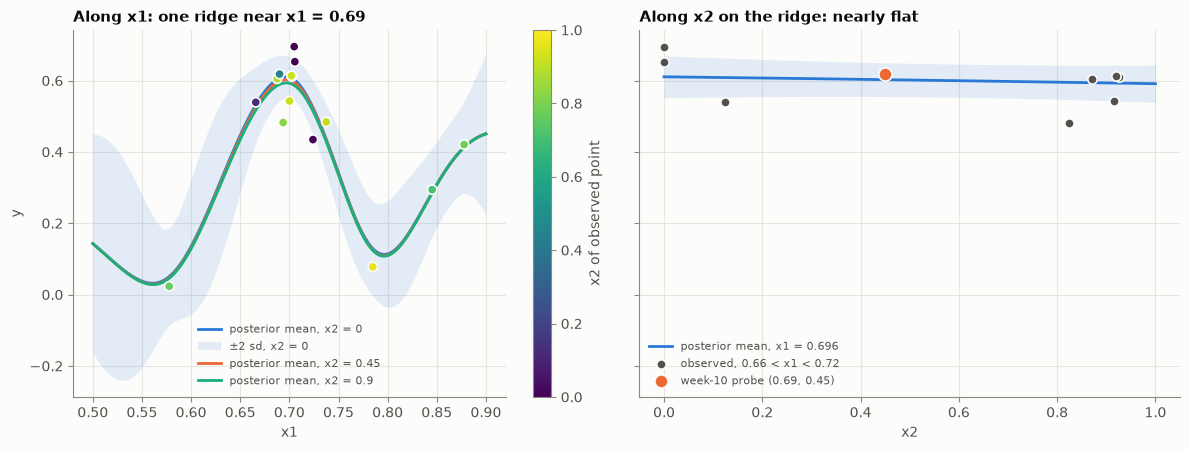

In [9]:
# Fig 3: slices of the recommended model
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6), sharey=True)
xs = np.linspace(0.5, 0.9, 300)
for x2v, col, lab in [(0.0, BLUE, "x2 = 0"), (0.45, ORANGE, "x2 = 0.45"), (0.9, AQUA, "x2 = 0.9")]:
    Z = np.column_stack([xs, np.full_like(xs, x2v)])
    m, s = latent(Z)
    axes[0].plot(xs, m * y_std + y_mean, color=col, lw=2, label=f"posterior mean, {lab}")
    if x2v == 0.0:
        axes[0].fill_between(xs, (m - 2 * s) * y_std + y_mean, (m + 2 * s) * y_std + y_mean,
                             color=col, alpha=0.12, lw=0, label="±2 sd, x2 = 0")
near = (X[:, 0] > 0.5) & (X[:, 0] < 0.9)
sc = axes[0].scatter(X[near, 0], y[near], c=X[near, 1], cmap="viridis", vmin=0, vmax=1, s=45,
                     edgecolor=SURFACE, linewidth=1.2, zorder=4)
fig.colorbar(sc, ax=axes[0], label="x2 of observed point")
axes[0].set_xlabel("x1"); axes[0].set_ylabel("y")
axes[0].set_title("Along x1: one ridge near x1 = 0.69")
axes[0].legend(frameon=False, fontsize=8, loc="lower center", labelcolor=INK2)
x2s = np.linspace(0, 1, 300)
Z = np.column_stack([np.full_like(x2s, x_mean[0]), x2s])
m, s = latent(Z)
axes[1].plot(x2s, m * y_std + y_mean, color=BLUE, lw=2, label=f"posterior mean, x1 = {x_mean[0]:.3f}")
axes[1].fill_between(x2s, (m - 2 * s) * y_std + y_mean, (m + 2 * s) * y_std + y_mean, color=BLUE, alpha=0.12, lw=0)
ridge = (X[:, 0] > 0.66) & (X[:, 0] < 0.72)
axes[1].scatter(X[ridge, 1], y[ridge], s=45, color=INK2, edgecolor=SURFACE, linewidth=1.2, zorder=4,
                label="observed, 0.66 < x1 < 0.72")
axes[1].scatter(X[-1, 1], y[-1], s=90, color=ORANGE, edgecolor=SURFACE, linewidth=1.2, zorder=5,
                label="week-10 probe (0.69, 0.45)")
axes[1].set_xlabel("x2"); axes[1].set_title("Along x2 on the ridge: nearly flat")
axes[1].legend(frameon=False, fontsize=8, loc="lower left", labelcolor=INK2)
fig.tight_layout(); 

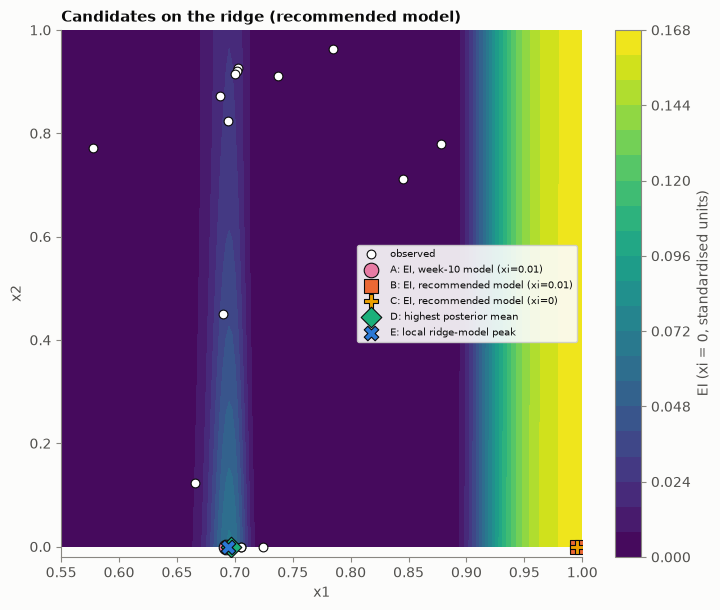

In [10]:
# Fig 4: EI map with candidates (zoomed)
fig, ax = plt.subplots(figsize=(7.4, 6.2))
lo1, hi1 = 0.55, 1.0
sel = (G1 >= lo1) & (G1 <= hi1)
E = ei(grid, 0.0).reshape(G1.shape)
cf = ax.contourf(G1, G2, np.where(sel, E, np.nan), levels=20, cmap="viridis")
fig.colorbar(cf, ax=ax, label="EI (xi = 0, standardised units)")
ax.scatter(X[:, 0], X[:, 1], s=40, color="white", edgecolor=INK, linewidth=0.8, zorder=3, label="observed")
marks = [("o", MAGENTA), ("s", ORANGE), ("P", YELLOW), ("D", AQUA), ("X", BLUE)]
for (name, xc), (m_, c_) in zip(cands.items(), marks):
    ax.scatter(*xc, s=110, marker=m_, color=c_, edgecolor=INK, linewidth=0.8, zorder=5, label=name)
ax.set_xlim(lo1, hi1); ax.set_ylim(-0.02, 1.0)
ax.set_xlabel("x1"); ax.set_ylabel("x2")
ax.set_title("Candidates on the ridge (recommended model)")
ax.legend(frameon=True, fontsize=7.5, loc="center right", framealpha=0.9)
ax.grid(False)
fig.tight_layout(); 

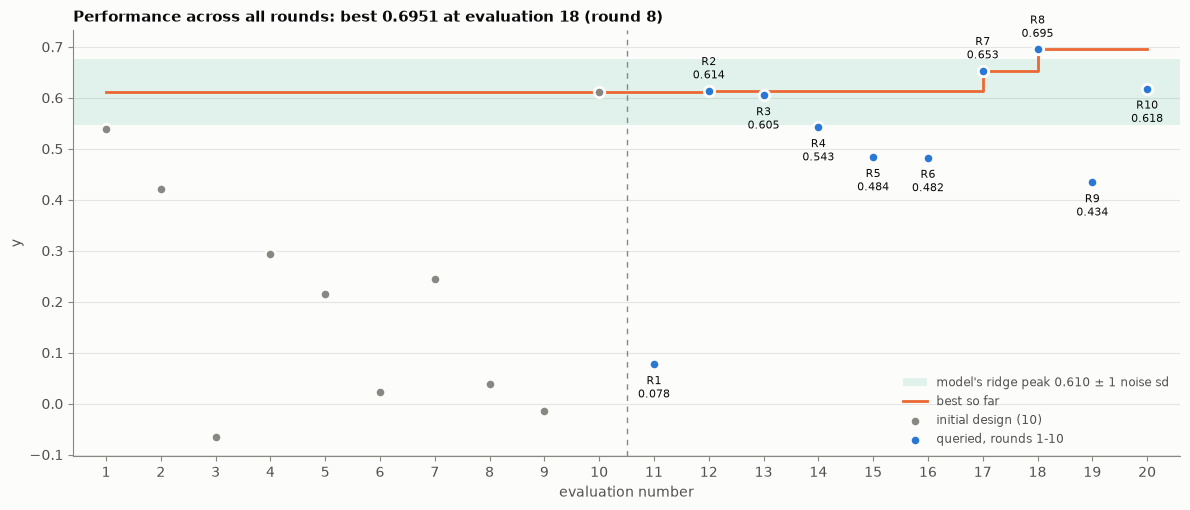

In [ ]:
# Fig 5: performance across all rounds
idx = np.arange(1, n + 1)
best = np.maximum.accumulate(np.r_[np.full(N_INITIAL, y[:N_INITIAL].max()), y[N_INITIAL:]])
peak_mean = latent(x_mean[None])[0][0] * y_std + y_mean
fig, ax = plt.subplots(figsize=(12, 5.2))
ax.axhspan(peak_mean - noise_sd_raw, peak_mean + noise_sd_raw, color=AQUA, alpha=0.12, lw=0,
           label=f"model's ridge peak {peak_mean:.3f} ± 1 noise sd")
ax.axvline(N_INITIAL + 0.5, color=MUTED, lw=1, ls=(0, (4, 4)))
ax.step(idx, best, where="post", color=ORANGE, lw=2, label="best so far", zorder=2)
ax.scatter(idx[:N_INITIAL], y[:N_INITIAL], s=56, color=MUTED, edgecolor=SURFACE, linewidth=2,
           label=f"initial design ({N_INITIAL})", zorder=3)
ax.scatter(idx[N_INITIAL:], y[N_INITIAL:], s=56, color=BLUE, edgecolor=SURFACE, linewidth=2,
           label=f"queried, rounds 1-{n - N_INITIAL}", zorder=3)
for i in range(N_INITIAL, n):
    ax.annotate(f"R{i - N_INITIAL + 1}\n{y[i]:.3f}", (idx[i], y[i]),
                xytext=(0, 9 if y[i] >= best[i] else -24), textcoords="offset points",
                ha="center", fontsize=8, color=INK)
ax.set_xticks(idx); ax.set_xlim(0.4, n + 0.6)
ax.set_xlabel("evaluation number"); ax.set_ylabel("y")
ax.set_title(f"Performance across all rounds: best {y.max():.4f} at evaluation {obs + 1} (round {obs - N_INITIAL + 1})")
ax.legend(frameon=False, loc="lower right", fontsize=8.5, labelcolor=INK2)
ax.grid(axis="x", visible=False)
fig.tight_layout(); 